In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 1000

df = pd.DataFrame({
    'Customer_ID': range(1001, 1001 + n),

    'Age': np.random.randint(18, 66, n).astype(float),

    'Monthly_Income': np.random.lognormal(
        mean=10.5, sigma=0.8, size=n
    ).round(2),

    'Website_Visits': np.random.randint(1, 31, n),

    'Annual_Spending': np.random.exponential(
        scale=1200, size=n
    ).round(2),

    'Membership': np.random.choice(
        ['Silver', 'Gold', 'Platinum'],
        n,
        p=[0.5, 0.3, 0.2]
    ),

    'Preferred_Category': np.random.choice(
        ['Serum', 'Sunscreen', 'Moisturizer', 'Facewash'],
        n
    ),

    'Product_Size': np.random.choice(
        ['30ml', '50ml', '100ml', '150ml', '50g', '100g'],
        n
    ),

    'Last_Purchase_Date': pd.to_datetime(
        np.random.choice(
            pd.date_range('2025-01-01', '2026-09-30'),
            n
        )
    ),

    'Days_On_Website': np.random.randint(1, 21, n).astype(float),

    'Monthly_Profit_Change': np.random.normal(
        loc=20, scale=150, size=n
    ).round(2)
})

# Create purchase target before introducing missing values

probability = (
    0.10
    + df['Website_Visits'] * 0.012
    + (df['Membership'] == 'Platinum') * 0.15
    + (df['Annual_Spending'] > 1500) * 0.12
    + (df['Days_On_Website'] > 10) * 0.08
)

probability = np.clip(probability, 0.05, 0.95)

df['Purchased'] = np.random.binomial(1, probability)

# Introduce missing values

for col, fraction in {
    'Age': 0.05,
    'Monthly_Income': 0.12,
    'Membership': 0.08,
    'Preferred_Category': 0.06,
    'Days_On_Website': 0.10
}.items():

    missing_idx = np.random.choice(
        df.index,
        size=int(n * fraction),
        replace=False
    )

    df.loc[missing_idx, col] = np.nan

# Introduce a few zero values for transformation practice

zero_idx = np.random.choice(df.index, size=20, replace=False)

df.loc[zero_idx, 'Monthly_Profit_Change'] = 0

df.head()

,Customer_ID,Age,Monthly_Income,Website_Visits,Annual_Spending,Membership,Preferred_Category,Product_Size,Last_Purchase_Date,Days_On_Website,Monthly_Profit_Change,Purchased
0,1001,56.0,9877.02,9,992.60,Gold,Serum,100ml,2025-10-10,19.0,-278.20,0
1,1002,46.0,NaN,26,698.41,Silver,Serum,50ml,2025-02-27,15.0,-265.50,0
2,1003,32.0,44702.20,16,1116.94,Gold,Serum,150ml,2026-06-21,6.0,-101.30,1
3,1004,60.0,17615.72,5,3012.04,Gold,Moisturizer,50g,2025-03-14,16.0,0.00,0
4,1005,NaN,60528.76,25,539.80,Gold,Serum,100g,2025-05-09,NaN,-41.58,0


In [3]:
df.head(10)

,Customer_ID,Age,Monthly_Income,Website_Visits,Annual_Spending,Membership,Preferred_Category,Product_Size,Last_Purchase_Date,Days_On_Website,Monthly_Profit_Change,Purchased
0,1001,56.0,9877.02,9,992.60,Gold,Serum,100ml,2025-10-10,19.0,-278.20,0
1,1002,46.0,NaN,26,698.41,Silver,Serum,50ml,2025-02-27,15.0,-265.50,0
2,1003,32.0,44702.20,16,1116.94,Gold,Serum,150ml,2026-06-21,6.0,-101.30,1
3,1004,60.0,17615.72,5,3012.04,Gold,Moisturizer,50g,2025-03-14,16.0,0.00,0
4,1005,NaN,60528.76,25,539.80,Gold,Serum,100g,2025-05-09,NaN,-41.58,0
5,1006,38.0,9612.16,20,1552.31,Platinum,Sunscreen,100g,2026-08-22,16.0,41.79,1
6,1007,56.0,34445.59,29,2698.31,Gold,Facewash,50g,2026-03-02,18.0,215.50,1
7,1008,36.0,NaN,10,730.52,Silver,Facewash,150ml,2025-05-05,20.0,36.55,1
8,1009,40.0,21558.62,18,703.21,Platinum,Serum,100g,2025-03-08,16.0,31.38,1
9,1010,28.0,37718.99,3,1105.92,Platinum,Serum,50ml,2025-01-06,11.0,113.40,0


In [4]:
df.shape

(1000, 12)

In [5]:
df.dtypes

Customer_ID                       int64
Age                             float64
Monthly_Income                  float64
Website_Visits                    int32
Annual_Spending                 float64
Membership                          str
Preferred_Category                  str
Product_Size                        str
Last_Purchase_Date       datetime64[us]
Days_On_Website                 float64
Monthly_Profit_Change           float64
Purchased                         int32
dtype: object

In [6]:
df.describe()

,Customer_ID,Age,Monthly_Income,Website_Visits,Annual_Spending,Last_Purchase_Date,Days_On_Website,Monthly_Profit_Change,Purchased
count,1000.000000,950.000000,880.000000,1000.000000,1000.00000,1000,900.00000,1000.000000,1000.000000
mean,1500.500000,41.667368,52319.950909,15.616000,1240.22056,2025-11-09 09:02:52.800000,10.52000,22.640000,0.393000
min,1001.000000,18.000000,3579.560000,1.000000,0.53000,2025-01-01 00:00:00,1.00000,-439.670000,0.000000
25%,1250.750000,30.000000,22895.952500,8.000000,395.45000,2025-06-05 18:00:00,6.00000,-74.712500,0.000000
50%,1500.500000,42.000000,37809.780000,16.000000,917.98000,2025-11-05 12:00:00,11.00000,17.680000,0.000000
75%,1750.250000,53.000000,63720.185000,23.000000,1725.16250,2026-04-13 12:00:00,15.00000,120.505000,1.000000
max,2000.000000,65.000000,298315.120000,30.000000,9231.41000,2026-09-30 00:00:00,20.00000,559.920000,1.000000
std,288.819436,13.684881,45928.198498,8.722306,1173.37518,NaN,5.78774,144.599082,0.488661


In [7]:
df.isnull().sum()

Customer_ID                0
Age                       50
Monthly_Income           120
Website_Visits             0
Annual_Spending            0
Membership                80
Preferred_Category        60
Product_Size               0
Last_Purchase_Date         0
Days_On_Website          100
Monthly_Profit_Change      0
Purchased                  0
dtype: int64

In [8]:
df.isnull().mean()*100

Customer_ID               0.0
Age                       5.0
Monthly_Income           12.0
Website_Visits            0.0
Annual_Spending           0.0
Membership                8.0
Preferred_Category        6.0
Product_Size              0.0
Last_Purchase_Date        0.0
Days_On_Website          10.0
Monthly_Profit_Change     0.0
Purchased                 0.0
dtype: float64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
import matplotlib.pyplot as plt

In [11]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import seaborn as sns

C:\Users\chauh\AppData\Local\Temp\ipykernel_17060\525830866.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Purchased', data=df, palette='Set2')


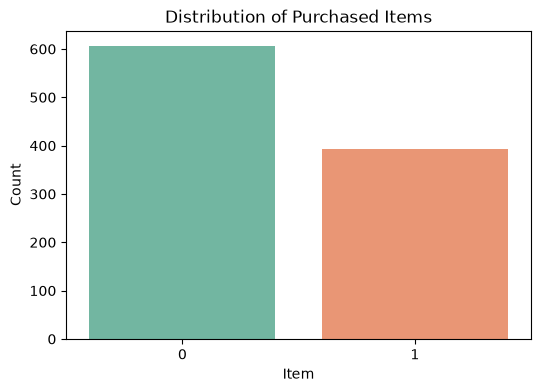

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Purchased', data=df, palette='Set2')
plt.title("Distribution of Purchased Items")
plt.xlabel("Item")
plt.ylabel("Count")
plt.show()

In [14]:
complete_rows = len(df.dropna())
print("Complete Rows:", complete_rows)

Complete Rows: 643


In [15]:
missing_rows = len(df) - complete_rows
print("Rows with Missing Values:", missing_rows)

Rows with Missing Values: 357


In [16]:
loss_percentage = (missing_rows / len(df)) * 100
print("Data Loss Percentage:", loss_percentage)

Data Loss Percentage: 35.699999999999996


In [17]:
df['Monthly_Income'].dtypes

dtype('float64')

In [18]:
df.groupby(df['Monthly_Income'].isnull())['Purchased'].mean()*100

Monthly_Income
False    38.295455
True     46.666667
Name: Purchased, dtype: float64

In [19]:
df.groupby(df['Days_On_Website'].isnull())['Purchased'].mean()*100

Days_On_Website
False    39.111111
True     41.000000
Name: Purchased, dtype: float64

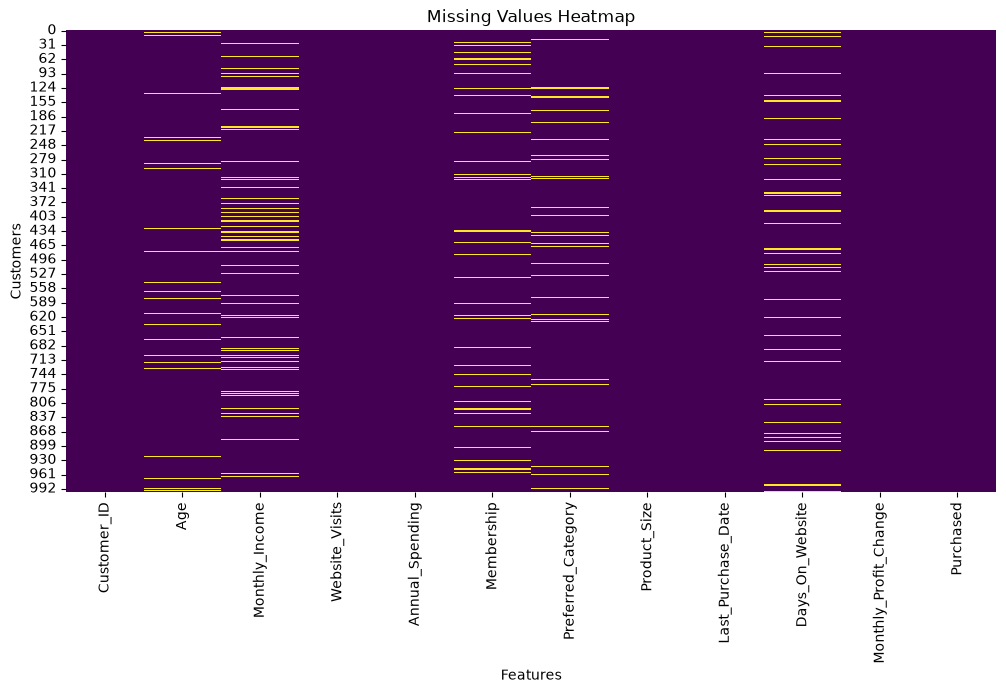

In [20]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title('Missing Values Heatmap')
plt.xlabel('Features')
plt.ylabel('Customers')

plt.show()

In [21]:
df_cca = df.dropna()

In [22]:
print("Mean Age of Original Data:", df['Age'].mean())
print("Mean Age of CCA Data:", df_cca['Age'].mean())
print("Median Monthly Income of Original Data:", df['Monthly_Income'].median())
print("Median Monthly Income of CCA Data:", df_cca['Monthly_Income'].median())
print("Mean Annual Spending of Original Data:", df['Annual_Spending'].mean())
print("Mean Annual Spending of CCA Data:", df_cca['Annual_Spending'].mean())

Mean Age of Original Data: 41.66736842105263
Mean Age of CCA Data: 41.52099533437014
Median Monthly Income of Original Data: 37809.78
Median Monthly Income of CCA Data: 37610.9
Mean Annual Spending of Original Data: 1240.22056
Mean Annual Spending of CCA Data: 1234.1527371695179


In [23]:
Purchase_Rate_Of_Original_Data = (df['Purchased'].mean()*100)

In [24]:
Purchase_Rate_Of_CCA_Data = (df_cca['Purchased'].mean()*100)

In [25]:
Difference_Percentage_Of_Purchase_Rate = (Purchase_Rate_Of_Original_Data - Purchase_Rate_Of_CCA_Data) 

In [26]:
print("Original Purchase Rate:", Purchase_Rate_Of_Original_Data)
print("CCA Purchase Rate:", Purchase_Rate_Of_CCA_Data)
print("Difference:", Difference_Percentage_Of_Purchase_Rate, "percentage points")

Original Purchase Rate: 39.300000000000004
CCA Purchase Rate: 39.19129082426128
Difference: 0.10870917573872418 percentage points


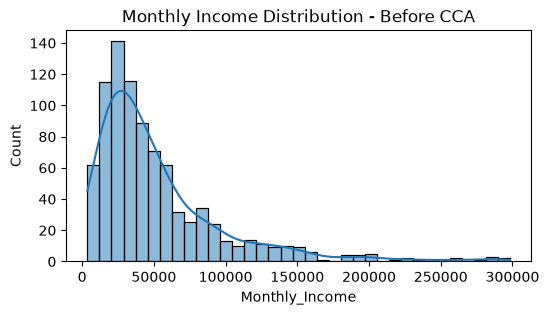

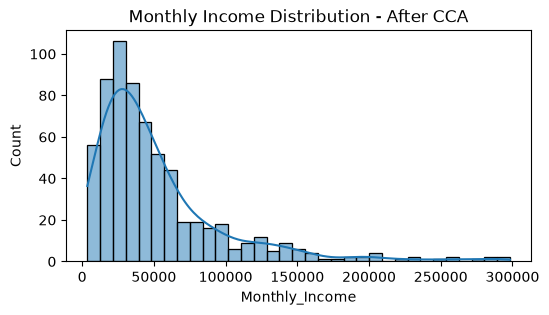

In [27]:
plt.figure(figsize=(6,3))
sns.histplot(df['Monthly_Income'], kde = True)
plt.title('Monthly Income Distribution - Before CCA')
plt.show()

plt.figure(figsize=(6,3))
sns.histplot(df_cca['Monthly_Income'], kde = True)
plt.title('Monthly Income Distribution - After CCA')
plt.show()

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns='Purchased'), df['Purchased'],
    test_size=0.2, random_state=42, stratify=df['Purchased']
)

In [30]:
from sklearn.impute import SimpleImputer

In [31]:
SI = SimpleImputer(strategy='mean')

In [32]:
Age_Imputed_Data = SI.fit_transform(X_train[['Age']])
Monthly_Income_Imputed_Data = SI.fit_transform(X_train[['Monthly_Income']])
Days_On_Website_Imputed_Data = SI.fit_transform(X_train[['Days_On_Website']])

In [33]:
df_mean_imputed = pd.DataFrame({
    'Age': Age_Imputed_Data.ravel(),
    'Monthly_Income': Monthly_Income_Imputed_Data.ravel(),
    'Days_On_Website': Days_On_Website_Imputed_Data.ravel()},
    index=X_train.index
)
df_mean_imputed.head()

,Age,Monthly_Income,Days_On_Website
971,48.0,95482.00,4.0000
697,27.0,50566.23,20.0000
966,47.0,23123.44,10.5574
199,41.0,31345.10,9.0000
35,61.0,191055.77,13.0000


In [34]:
numerical_cols = ['Age', 'Monthly_Income', 'Days_On_Website']

In [35]:
SI_ = SimpleImputer(strategy='median')

In [36]:
median_imputed_data = SI_.fit_transform(X_train[numerical_cols])

In [37]:
df_median_imputed = pd.DataFrame(
    median_imputed_data,
    columns=numerical_cols,
    index=X_train.index
)

In [38]:
df_median_imputed.head()

,Age,Monthly_Income,Days_On_Website
971,48.0,95482.00,4.0
697,27.0,50566.23,20.0
966,47.0,23123.44,11.0
199,41.0,31345.10,9.0
35,61.0,191055.77,13.0


In [39]:
df_mean_imputed.isnull().sum()
df_median_imputed.isnull().sum()

Age                0
Monthly_Income     0
Days_On_Website    0
dtype: int64

In [40]:
comparison = pd.DataFrame({
    'Original Mean': X_train[numerical_cols].mean(),
    'Mean Imputed Mean': df_mean_imputed.mean(),
    'Median Imputed Mean': df_median_imputed.mean(),

    'Original Median': X_train[numerical_cols].median(),
    'Mean Imputed Median': df_mean_imputed.median(),
    'Median Imputed Median': df_median_imputed.median()
})

comparison

,Original Mean,Mean Imputed Mean,Median Imputed Mean,Original Median,Mean Imputed Median,Median Imputed Median
Age,41.808650,41.808650,41.863750,43.00,41.80865,43.00
Monthly_Income,51994.783042,51994.783042,50269.195325,38592.16,44745.17000,38592.16
Days_On_Website,10.557400,10.557400,10.600000,11.00,10.55740,11.00


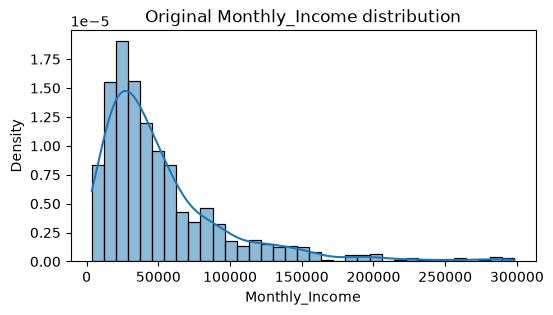

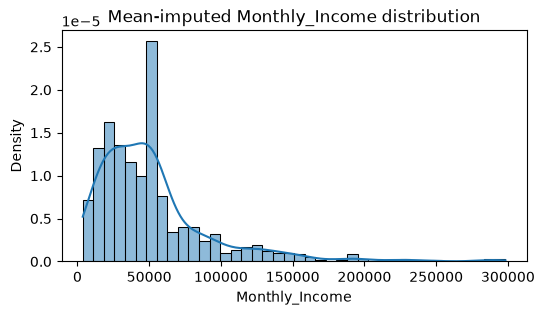

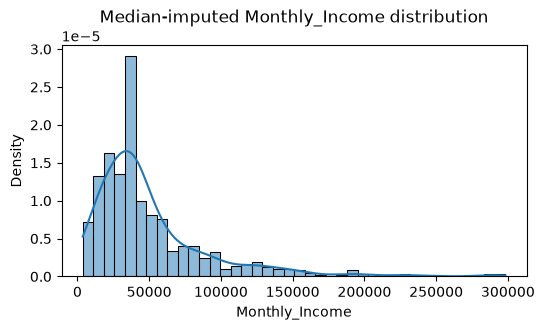

In [41]:
plt.figure(figsize=(6,3))
sns.histplot(df['Monthly_Income'], kde=True, stat='density')
plt.title('Original Monthly_Income distribution')
plt.show()

plt.figure(figsize=(6,3))
sns.histplot(df_mean_imputed['Monthly_Income'], kde=True, stat='density')
plt.title('Mean-imputed Monthly_Income distribution')
plt.show()

plt.figure(figsize=(6,3))
sns.histplot(df_median_imputed['Monthly_Income'], kde=True, stat='density')
plt.title('Median-imputed Monthly_Income distribution')
plt.show()

In [42]:
print(df['Monthly_Income'].var())
print(df_mean_imputed['Monthly_Income'].var())
print(df_median_imputed['Monthly_Income'].var())

2109399417.2898893
1708416573.5455031
1728591540.977998


In [43]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method='yeo-johnson')

income_transformed = pt.fit_transform(
    df_median_imputed[['Monthly_Income']]
)

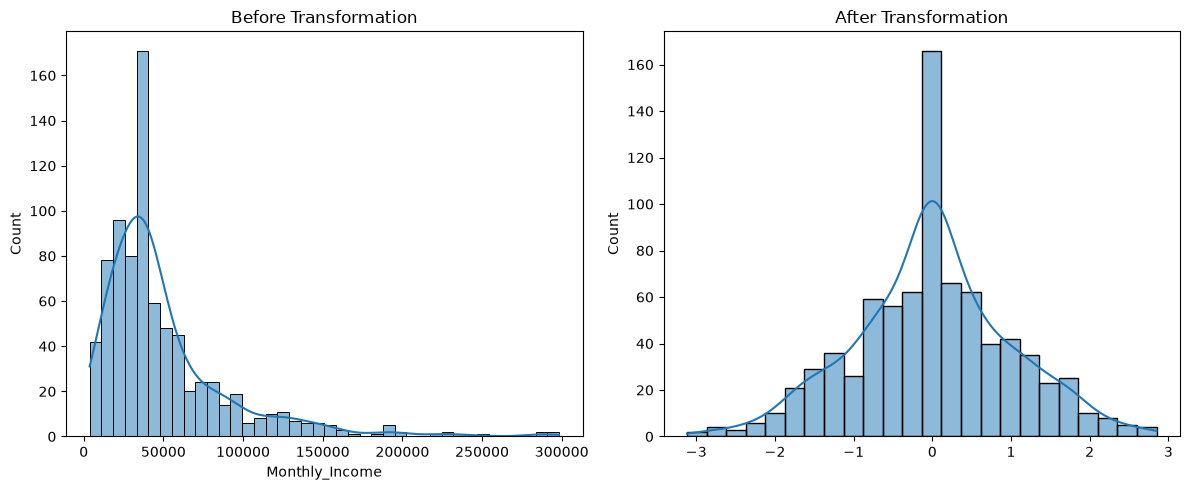

In [44]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
sns.histplot(df_median_imputed['Monthly_Income'], kde=True, ax=ax[0])
ax[0].set_title('Before Transformation')
sns.histplot(income_transformed.ravel(), kde=True, ax=ax[1])
ax[1].set_title('After Transformation')
plt.tight_layout()
plt.show()

In [45]:
df_median_imputed['Monthly_Income'].skew()

np.float64(2.393460636098327)

In [46]:
series1 = pd.Series(income_transformed.ravel())

In [47]:
series1.skew()

np.float64(0.0010181778417212735)

In [48]:
df_median_imputed['Monthly_Income'].var()

np.float64(1728591540.977998)

In [49]:
series1.var()

np.float64(1.0012515644555695)

In [50]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method='yeo-johnson', standardize=False)

income_transformed_unstandardized = pt.fit_transform(
    df_median_imputed[['Monthly_Income']]
)

In [51]:
df_median_imputed['Monthly_Income'].skew()

np.float64(2.393460636098327)

In [52]:
series2 = pd.Series(income_transformed_unstandardized.ravel())

In [53]:
series2.skew()

np.float64(0.0010181778417225611)

In [54]:
df_median_imputed['Monthly_Income'].var()

np.float64(1728591540.977998)

In [55]:
series2.var()

np.float64(0.8555651058612028)

In [56]:
pt.lambdas_

array([0.02198805])

In [57]:
df_median_imputed['Monthly_Income'].min()

np.float64(3718.84)

In [66]:
(df_median_imputed['Monthly_Income']<= 0).sum()

np.int64(0)

In [67]:
df_median_imputed['Monthly_Income'].isna().sum()

np.int64(0)

In [75]:
pt_boxcox = PowerTransformer(method='box-cox')

In [76]:
income_boxcox = pt_boxcox.fit_transform(df_median_imputed[['Monthly_Income']])

In [77]:
df_median_imputed['Monthly_Income'].skew()

np.float64(2.393460636098327)

In [78]:
series2.skew()

np.float64(0.0010181778417225611)

In [79]:
series3 = pd.Series(income_boxcox.ravel())

In [80]:
series3.skew()

np.float64(0.001020293922186972)

In [87]:
income_recovered = pt_boxcox.inverse_transform(income_boxcox)

In [93]:
income_recovered_r = income_recovered.ravel()

In [96]:
income_recovered_r[:5]

array([ 95482.  ,  50566.23,  23123.44,  31345.1 , 191055.77])

In [98]:
df_median_imputed['Monthly_Income'].head()

971     95482.00
697     50566.23
966     23123.44
199     31345.10
35     191055.77
Name: Monthly_Income, dtype: float64

In [99]:
np.max(np.abs(df_median_imputed['Monthly_Income'] - income_recovered_r))

np.float64(9.604264050722122e-10)

In [100]:
df_median_imputed.columns

Index(['Age', 'Monthly_Income', 'Days_On_Website'], dtype='str')

In [103]:
df_median_imputed.select_dtypes(include='number')

,Age,Monthly_Income,Days_On_Website
971,48.0,95482.00,4.0
697,27.0,50566.23,20.0
966,47.0,23123.44,11.0
199,41.0,31345.10,9.0
35,61.0,191055.77,13.0
...,...,...,...
314,24.0,34906.52,1.0
510,29.0,13621.27,13.0
119,50.0,29197.00,20.0
186,56.0,23483.77,6.0


In [104]:
df_median_imputed.describe()

,Age,Monthly_Income,Days_On_Website
count,800.000000,800.000000,800.000000
mean,41.863750,50269.195325,10.600000
std,13.427604,41576.333905,5.486586
min,18.000000,3718.840000,1.000000
25%,31.000000,24640.530000,6.000000
50%,43.000000,38592.160000,11.000000
75%,53.000000,59222.422500,15.000000
max,65.000000,298315.120000,20.000000


In [105]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer

In [114]:
ct = ColumnTransformer(
    transformers=[
        ('Std_Scaled', StandardScaler(), ['Days_On_Website']),
        ('Min_Max_Scaled', MinMaxScaler(), ['Age']),
        ('Robust_Scaled', RobustScaler(), ['Monthly_Income'])
    ],
    remainder='passthrough'
)

In [116]:
scaled_data = ct.fit_transform(df_median_imputed)

In [118]:
scaled_data[:5]

array([[-1.20368634,  0.63829787,  1.64507596],
       [ 1.71434115,  0.19148936,  0.34625259],
       [ 0.07295069,  0.61702128, -0.44730693],
       [-0.29180275,  0.4893617 , -0.20956227],
       [ 0.43770412,  0.91489362,  4.40876999]])

In [126]:
scaled_df = pd.DataFrame(
    scaled_data,
    columns=[
        'Days_On_Website_Scaled',
        'Age_Scaled',
        'Monthly_Income_Scaled'
]
)
scaled_df.describe()

,Days_On_Website_Scaled,Age_Scaled,Monthly_Income_Scaled
count,8.000000e+02,800.000000,800.000000
mean,7.105427e-17,0.507739,0.337663
std,1.000626e+00,0.285694,1.202257
min,-1.750816e+00,0.000000,-1.008427
25%,-8.389329e-01,0.276596,-0.403437
50%,7.295069e-02,0.531915,0.000000
75%,8.024576e-01,0.744681,0.596563
max,1.714341e+00,1.000000,7.510374


In [163]:
from sklearn.preprocessing import KBinsDiscretizer

In [164]:
kbins = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')

In [165]:
age_binned = kbins.fit_transform(df_median_imputed[['Age']])

In [166]:
age_binned[:10]

array([[2.],
       [0.],
       [2.],
       [1.],
       [3.],
       [3.],
       [0.],
       [1.],
       [3.],
       [2.]])

In [167]:
age_binned_pd = pd.Series(age_binned.ravel())

In [168]:
age_binned_pd.value_counts()

2.0    217
3.0    202
0.0    194
1.0    187
Name: count, dtype: int64

In [169]:
kbins.bin_edges_

array([array([18., 31., 43., 53., 65.])], dtype=object)

In [170]:
from sklearn.preprocessing import Binarizer

In [171]:
bin = Binarizer(threshold=10)

In [172]:
website_binary = bin.fit_transform(df_median_imputed[['Days_On_Website']])

In [173]:
website_binary[:10]

array([[0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [1.]])

In [174]:
website_binary_p = pd.Series(website_binary.ravel())

In [175]:
website_binary_p.value_counts()

1.0    442
0.0    358
Name: count, dtype: int64

In [176]:
comparison_df = pd.DataFrame({
    'Original_Days': df_median_imputed['Days_On_Website'].to_numpy(),
    'Binary_Days': website_binary.ravel()
})

comparison_df.head(10)

,Original_Days,Binary_Days
0,4.0,0.0
1,20.0,1.0
2,11.0,1.0
3,9.0,0.0
4,13.0,1.0
5,18.0,1.0
6,2.0,0.0
7,11.0,1.0
8,13.0,1.0
9,13.0,1.0
